2025-09-16 18:37:09.793010: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1758047829.816393     205 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1758047829.823258     205 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Using device: cuda


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Training Classifier Head
Head Training Epoch [1/10] complete.
Head Training Epoch [2/10] complete.
Head Training Epoch [3/10] complete.
Head Training Epoch [4/10] complete.
Head Training Epoch [5/10] complete.
Head Training Epoch [6/10] complete.
Head Training Epoch [7/10] complete.
Head Training Epoch [8/10] complete.
Head Training Epoch [9/10] complete.
Head Training Epoch [10/10] complete.

Fine-Tuning Full Model
Epoch [1/50], Train Loss: 0.6392, Valid Loss: 0.6536, Valid Accuracy: 58.07%
Epoch [2/50], Train Loss: 0.6113, Valid Loss: 0.6445, Valid Accuracy: 61.78%
Epoch [3/50], Train Loss: 0.5870, Valid Loss: 0.5890, Valid Accuracy: 68.00%
Epoch [4/50], Train Loss: 0.5535, Valid Loss: 0.5819, Valid Accuracy: 69.33%
Epoch [5/50], Train Loss: 0.5447, Valid Loss: 0.6245, Valid Accuracy: 65.19%
Epoch [6/50], Train Loss: 0.5189, Valid Loss: 0.5965, Valid Accuracy: 65.78%
Epoch [7/50], Train Loss: 0.4989, Valid Loss: 0.5760, Valid Accuracy: 68.44%
Epoch [8/50], Train Loss: 0.4756, Valid 

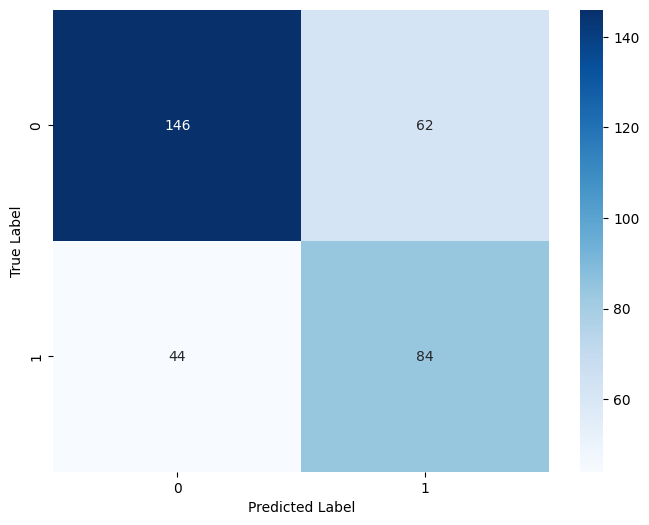

predictions saved to /kaggle/working/test_set_predictions.csv


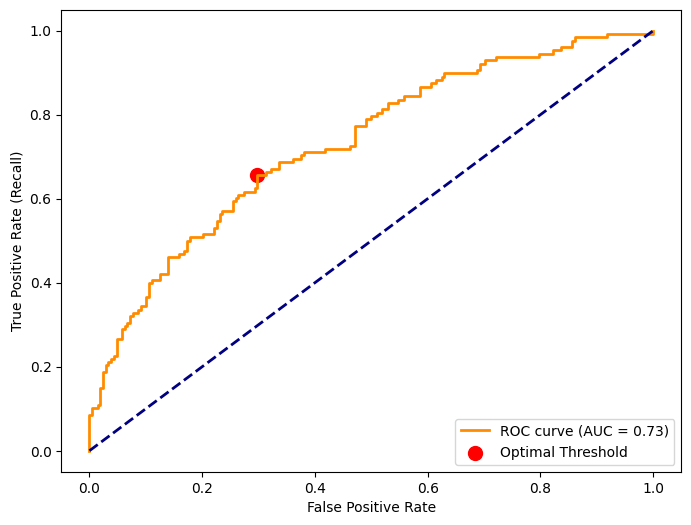

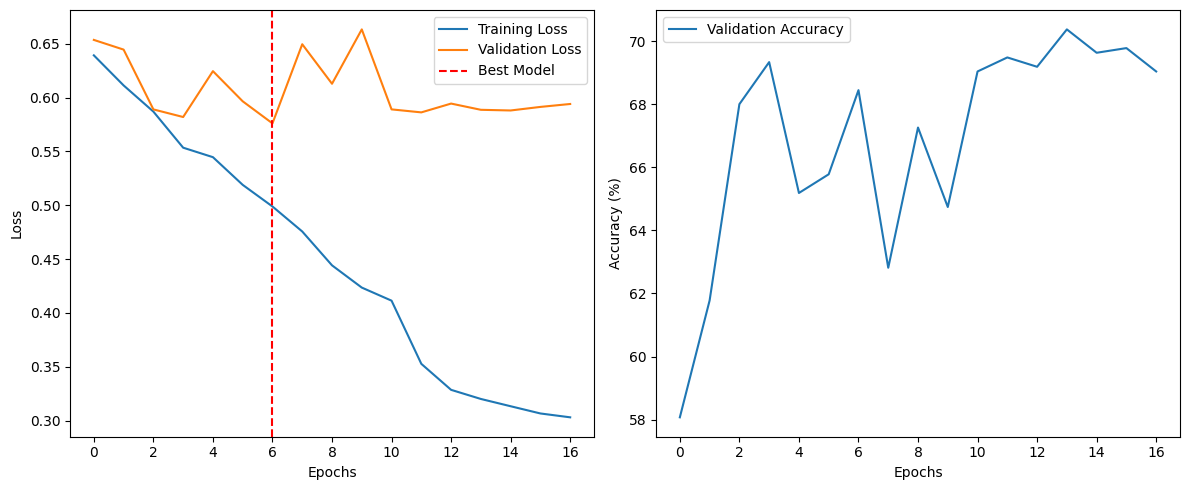

In [1]:
import torch
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from transformers import ViTForImageClassification, ViTImageProcessor
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from collections import Counter
import os
import random

def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

data_dir = '/kaggle/input/breast-cancer-detection'
train_dir = f'{data_dir}/train'
valid_dir = f'{data_dir}/valid'
test_dir = f'{data_dir}/test'

model_name = 'google/vit-base-patch16-224-in21k'
num_labels = 2
batch_size = 16
best_model_path = '/kaggle/working/best_model_checkpoint.pth'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Using device: {device}")

image_processor = ViTImageProcessor.from_pretrained(model_name)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop((image_processor.size['height'], image_processor.size['width']), scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_processor.image_mean, std=image_processor.image_std)
])
eval_transform = transforms.Compose([
    transforms.Resize((image_processor.size['height'], image_processor.size['width'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_processor.image_mean, std=image_processor.image_std)
])
train_dataset = ImageFolder(train_dir, transform=train_transform)
valid_dataset = ImageFolder(valid_dir, transform=eval_transform)
test_dataset = ImageFolder(test_dir, transform=eval_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

class_counts = Counter(train_dataset.targets)
total_samples = len(train_dataset.targets)
num_classes = len(class_counts)
class_weights = {i: total_samples / (num_classes * count) for i, count in class_counts.items()}
class_weights_tensor = torch.tensor([class_weights[i] for i in range(num_classes)], dtype=torch.float32).to(device)

model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=num_labels,
    ignore_mismatched_sizes=True
).to(device)
criterion = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)


print("\nTraining Classifier Head")
for param in model.vit.parameters():
    param.requires_grad = False
for param in model.classifier.parameters():
    param.requires_grad = True

optimizer_head = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3)
num_epochs_head = 10

for epoch in range(num_epochs_head):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_head.zero_grad()
        outputs = model(images).logits
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_head.step()
    print(f"Head Training Epoch [{epoch+1}/{num_epochs_head}] complete.")


print("\nFine-Tuning Full Model")
for param in model.parameters():
    param.requires_grad = True

optimizer_full = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_full, mode='min', factor=0.1, patience=3, verbose=False)
num_epochs_full = 50

best_valid_loss = float('inf')
early_stopping_patience = 10
early_stopping_counter = 0

train_losses, valid_losses, valid_accuracies = [], [], []

for epoch in range(num_epochs_full):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_full.zero_grad()
        outputs = model(images).logits
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_full.step()
        running_loss += loss.item()
    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    model.eval()
    running_loss = 0.0
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images).logits
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    valid_loss = running_loss / len(valid_loader)
    valid_losses.append(valid_loss)
    valid_accuracy = 100 * correct / total
    valid_accuracies.append(valid_accuracy)
    
    
    print(f'Epoch [{epoch+1}/{num_epochs_full}], Train Loss: {train_loss:.4f}, Valid Loss: {valid_loss:.4f}, Valid Accuracy: {valid_accuracy:.2f}%')

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), best_model_path)
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1

    if early_stopping_counter >= early_stopping_patience:
       
        print(f"Early stopping triggered at epoch {epoch+1}")
        break
    
    scheduler.step(valid_loss)

history_df = pd.DataFrame({
    'Epoch': range(1, len(train_losses) + 1),
    'Train Loss': train_losses,
    'Valid Loss': valid_losses,
    'Valid Accuracy': valid_accuracies
})
history_csv_path = '/kaggle/working/training_history_data.csv'
history_df.to_csv(history_csv_path, index=False)



print("\nEvaluation")
model.load_state_dict(torch.load(best_model_path))
model.eval()

all_probs, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images).logits
        probs = F.softmax(outputs, dim=1)
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
all_probs = np.array(all_probs)
all_labels = np.array(all_labels)
malignant_probs = all_probs[:, 1]
class_names = test_dataset.classes



#  OPTIMAL THRESHOLD 

fpr, tpr, thresholds = roc_curve(all_labels, malignant_probs, pos_label=1)
j_scores = tpr - fpr
ix = np.argmax(j_scores)
optimal_threshold = thresholds[ix]
print(f"Optimal threshold calculated: {optimal_threshold:.4f}")

predicted_label_indices = (malignant_probs >= optimal_threshold).astype(int)
cm_optimal = confusion_matrix(all_labels, predicted_label_indices)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_optimal, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
cm_optimal_path = f'/kaggle/working/confusion_matrix_optimal.png'
plt.savefig(cm_optimal_path, bbox_inches='tight')
plt.show()


# SAVE DATA TO CSV 
test_filenames = [os.path.basename(s[0]) for s in test_dataset.samples]
prediction_results = []
for i in range(len(test_filenames)):
    true_label_name = class_names[all_labels[i]]
    predicted_label_name = class_names[predicted_label_indices[i]]
    prediction_results.append({
        'Filename': test_filenames[i],
        'True Label': true_label_name,
        'Predicted Label': predicted_label_name,
        'Malignant Probability': f"{malignant_probs[i]:.4f}",
        'Prediction Correct?': true_label_name == predicted_label_name
    })
predictions_df = pd.DataFrame(prediction_results)
predictions_csv_path = '/kaggle/working/test_set_predictions.csv'
predictions_df.to_csv(predictions_csv_path, index=False)
print(f"predictions saved to {predictions_csv_path}")


# ROC CURVE AND HISTORY PLOTS ---
roc_auc = roc_auc_score(all_labels, malignant_probs)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.scatter(fpr[ix], tpr[ix], marker='o', color='red', s=100, label=f'Optimal Threshold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc="lower right")
roc_curve_path = '/kaggle/working/roc_curve.png'
plt.savefig(roc_curve_path, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(valid_losses, label='Validation Loss')
plt.axvline(np.argmin(valid_losses), color='r', linestyle='--', label=f'Best Model')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(valid_accuracies, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.tight_layout()
training_history_path = '/kaggle/working/training_history.png'
plt.savefig(training_history_path, bbox_inches='tight')
plt.show()

In [2]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score





accuracy = accuracy_score(all_labels, predicted_label_indices)
print(f"Accuracy: {accuracy:.4f}")



precision = precision_score(all_labels, predicted_label_indices, pos_label=1)
print(f"Precision: {precision:.4f}")

#Recall

recall = recall_score(all_labels, predicted_label_indices, pos_label=1)
print(f"Recall (Sensitivity): {recall:.4f}")



f1 = f1_score(all_labels, predicted_label_indices, pos_label=1)
print(f"F1-Score: {f1:.4f}")

Accuracy: 0.6845
Precision: 0.5753
Recall (Sensitivity): 0.6562
F1-Score: 0.6131


In [3]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 56.3 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 91.1 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 62.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 29.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 2.0

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loading trained model weights from: /kaggle/working/best_model_checkpoint.pth
Model loaded successfully.
Displaying Grad-CAM for: 21957_1719804083_png.rf.6c884f262682791cd15bfb597a8b0d76.jpg


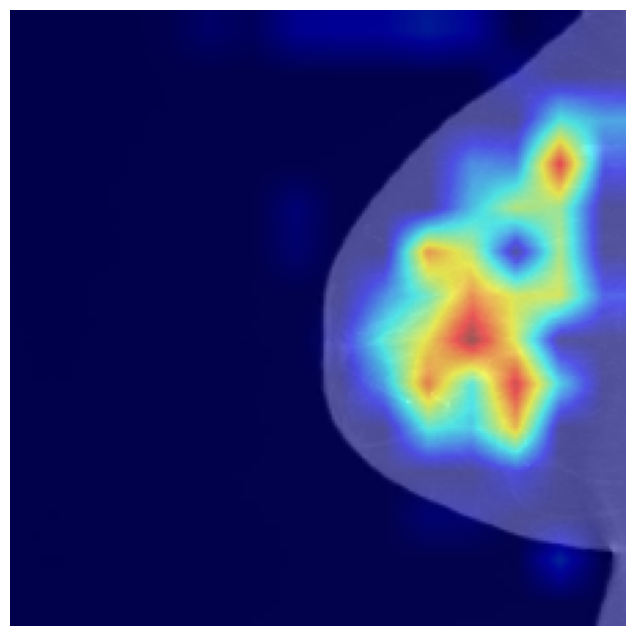

In [5]:
import torch
from torchvision import transforms
from transformers import ViTForImageClassification, ViTImageProcessor
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os
import cv2


best_model_path = '/kaggle/working/best_model_checkpoint.pth'


image_path = '/kaggle/input/breast-cancer-detection/test/1/21957_1719804083_png.rf.6c884f262682791cd15bfb597a8b0d76.jpg'

model_name = 'google/vit-base-patch16-224-in21k'
num_labels = 2
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- 2. THE CRITICAL STEP: Load Your Trained Model ---
# First, create the model architecture
model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=num_labels,
    ignore_mismatched_sizes=True
).to(device)


print(f"Loading trained model weights from: {best_model_path}")
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()
print("Model loaded successfully.")



class ViTModelWrapper(torch.nn.Module):
    def __init__(self, model):
        super(ViTModelWrapper, self).__init__()
        self.model = model

    def forward(self, x):
        return self.model(x).logits


image_processor = ViTImageProcessor.from_pretrained(model_name)
image = Image.open(image_path).convert("RGB")
preprocess_for_model = transforms.Compose([
    transforms.Resize((image_processor.size['height'], image_processor.size['width'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_processor.image_mean, std=image_processor.image_std)
])
input_tensor = preprocess_for_model(image).unsqueeze(0).to(device)
img_for_viz = cv2.imread(image_path, 1)[:, :, ::-1]
img_for_viz = cv2.resize(img_for_viz, (image_processor.size['height'], image_processor.size['width']))
img_for_viz = np.float32(img_for_viz) / 255


wrapped_model = ViTModelWrapper(model)
target_layers = [wrapped_model.model.vit.encoder.layer[-1].layernorm_before]


def reshape_transform(tensor):
    # This handles the tuple output from the HuggingFace model's forward pass
    if isinstance(tensor, tuple):
        tensor = tensor[0]
  
    result = tensor[:, 1:, :].reshape(tensor.size(0), 14, 14, tensor.size(2))
    result = result.permute(0, 3, 1, 2)
    return result

cam = GradCAM(model=wrapped_model, 
              target_layers=target_layers,
              reshape_transform=reshape_transform)

targets = [ClassifierOutputTarget(1)]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
grayscale_cam = grayscale_cam[0]


visualization = show_cam_on_image(img_for_viz, grayscale_cam, use_rgb=True)
print(f"Displaying Grad-CAM for: {os.path.basename(image_path)}")
plt.figure(figsize=(8, 8))
plt.imshow(visualization)
plt.axis('off')
plt.show()